In [3]:
!pip -q install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

In [4]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch the AI4I 2020 Predictive Maintenance dataset
dataset = fetch_ucirepo(id=601)

# Separate features and targets
X = dataset.data.features
y = dataset.data.targets

# Combine them for exploration
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:
Type                    object
Air temperature        float64
Process temperature    float64
Rotational speed         int64
Torque                 float64
Tool wear                int64
Machine failure          int64
TWF                      int64
HDF                      int64
PWF                      int64
OSF                      int64
RNF                      int64
dtype: object

Missing values:
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64

Duplicate rows:
0

Statistical summary:


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset = fetch_ucirepo(id=601)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (10000, 12)


In [7]:
failure_counts = df["Machine failure"].value_counts().sort_index()

print("Machine failure counts:")
print(failure_counts)

failure_percentage = (
    df["Machine failure"].value_counts(normalize=True).sort_index() * 100
)

print("\nFailure percentages:")
print(failure_percentage)

Machine failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


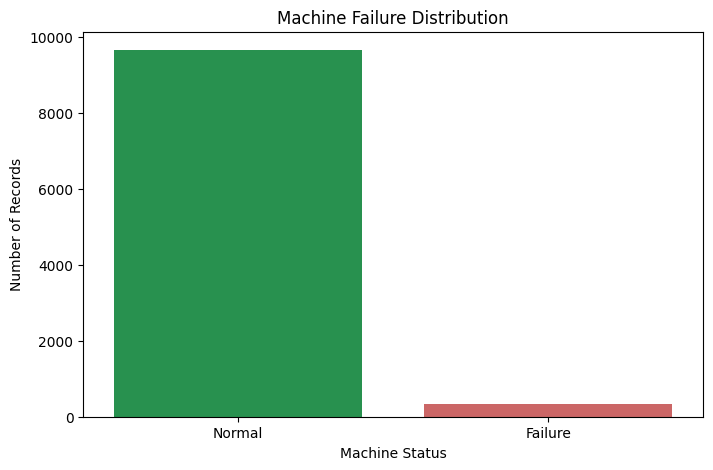

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Machine failure",
    hue="Machine failure",
    palette=["#16A34A", "#DC5555"],
    legend=False
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Status")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Normal", "Failure"])

plt.show()

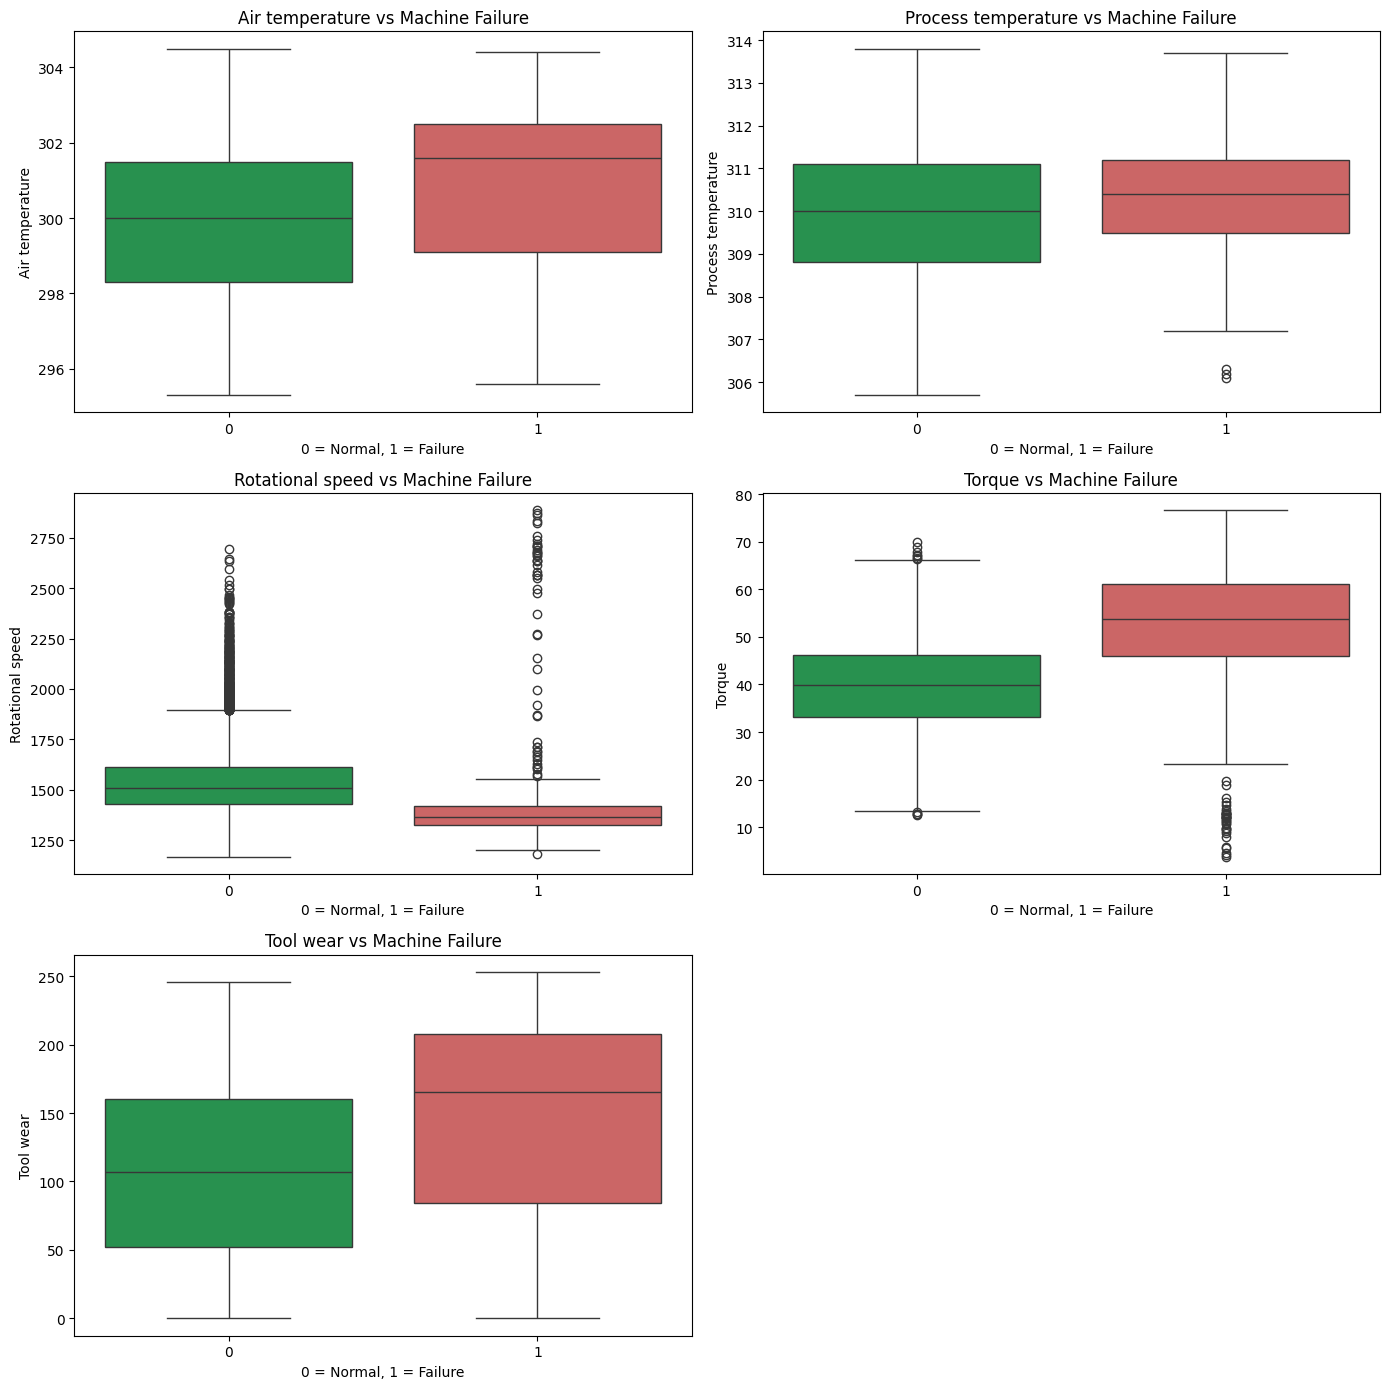

In [9]:
features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        hue="Machine failure",
        ax=axes[i],
        palette=["#16A34A", "#DC5555"],
        legend=False
    )

    axes[i].set_title(f"{feature} vs Machine Failure")
    axes[i].set_xlabel("0 = Normal, 1 = Failure")

axes[5].axis("off")

plt.tight_layout()
plt.show()

Failure percentage by machine type:


Machine failure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


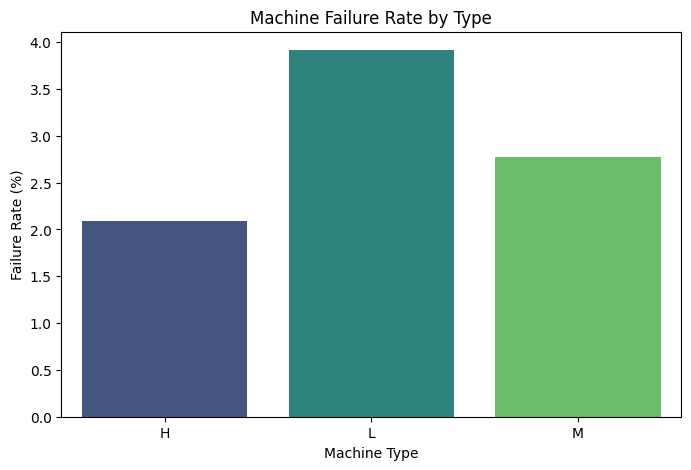

In [10]:
# Calculate failure rate for each machine type
type_failure = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    normalize="index"
) * 100

print("Failure percentage by machine type:")
display(type_failure)

# Visualize failure rates
failure_rate = df.groupby("Type")["Machine failure"].mean() * 100

plt.figure(figsize=(8, 5))

sns.barplot(
    x=failure_rate.index,
    y=failure_rate.values,
    hue=failure_rate.index,
    palette="viridis",
    legend=False
)

plt.title("Machine Failure Rate by Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")

plt.show()

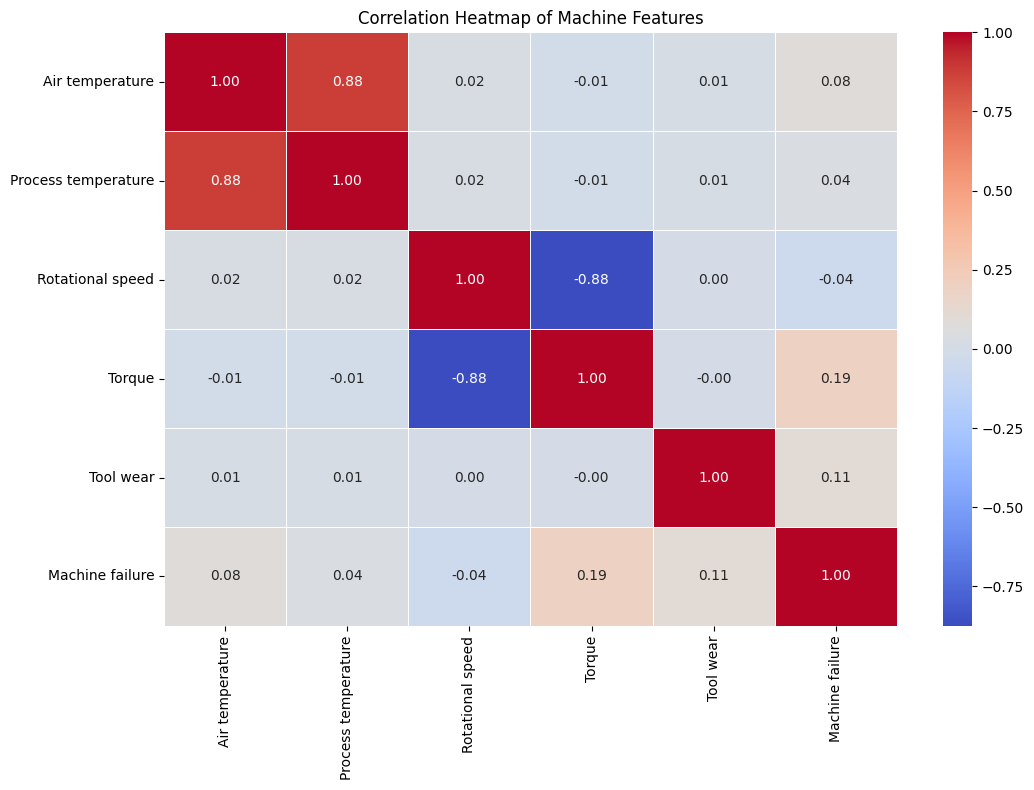

In [11]:
# Exclude failure-mode indicators to avoid leakage
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

correlation_data = df.drop(columns=leakage_columns)

# Calculate correlations between numerical columns
correlation_matrix = correlation_data.select_dtypes(
    include="number"
).corr()

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Machine Features")
plt.tight_layout()
plt.show()

In [12]:
# Define our prediction target
target = "Machine failure"

# Columns that must be excluded due to target leakage
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Create the feature list
feature_columns = [
    col for col in df.columns
    if col not in leakage_columns + [target]
]

print("Prediction target:")
print(target)

print("\nFeatures available for prediction:")
print(feature_columns)

print("\nLeakage columns excluded:")
print(leakage_columns)

print("\nNumber of input features:", len(feature_columns))

Prediction target:
Machine failure

Features available for prediction:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

Leakage columns excluded:
['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Number of input features: 6


# Phase 1: Dataset Exploration and EDA

## 1. Dataset Overview
- Dataset: AI4I 2020 Predictive Maintenance Dataset
- Total records: 10,000
- Total columns: 12
- Prediction target: Machine failure

## 2. Data Quality
- Missing values: 0
- Duplicate rows: 0
- Categorical feature: Type
- Numerical features: Temperature, rotational speed, torque and tool wear.

## 3. Failure Distribution
- Normal records: 9,661 (96.61%)
- Failure records: 339 (3.39%)
- Observation: The dataset has significant class imbalance.

## 4. Feature Analysis
- Failed machines show higher median torque.
- Failed machines show higher median tool wear.
- Failed machines show lower median rotational speed.
- Temperature differences between groups are relatively small.
- L-type machines have the highest observed failure rate (3.92%).
- H-type machines have the lowest observed failure rate (2.09%).

## 5. Correlation Analysis
- Air temperature and process temperature: +0.88
- Rotational speed and torque: -0.88
- Torque has the strongest positive linear correlation with machine failure among the numerical features: +0.19.

## 6. Target Leakage Prevention
Excluded columns:
- TWF
- HDF
- PWF
- OSF
- RNF

These columns describe failure outcomes and must not be used as prediction inputs.

## 7. Final ML Feature Selection
Input features:
1. Type
2. Air temperature
3. Process temperature
4. Rotational speed
5. Torque
6. Tool wear

Target: Machine failure

Total input features: 6

## 8. Conclusion
The dataset is clean and suitable for our initial ML experiments. However, the target is imbalanced, so model evaluation must focus on recall, precision, F1-score and PR-AUC rather than accuracy alone.

The observed relationships are associations and do not establish causation. The dataset is synthetic, so results should not be presented as proven real-world factory performance.